# 9 - Financial Trading

## Problem Definition

A financial institution seeks to automate trading decisions using reinforcement learning.

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque

In [ ]:
# 1. Fetch Financial Data
def fetch_data(ticker="AAPL", start="2022-01-01", end="2023-01-01"):
    df = yf.download(ticker, start=start, end=end)

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)

    df["Return"] = df["Close"].pct_change()
    df["SMA_5"] = df["Close"].rolling(window=5).mean()
    df.dropna(inplace=True)
    return df


# 2. Custom Trading Environment
class TradingEnv(gym.Env):
    def __init__(self, data, initial_balance=10000):
        super(TradingEnv, self).__init__()
        self.data = data.reset_index(drop=True)
        self.initial_balance = initial_balance

        # Actions: 0 = Hold, 1 = Buy (1 share), 2 = Sell (1 share)
        self.action_space = spaces.Discrete(3)

        # State: [Current Price, SMA_5, Return, Cash Balance, Shares Held]
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(5,), dtype=np.float32
        )
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.balance = float(self.initial_balance)
        self.shares_held = 0.0
        self.net_worth = float(self.initial_balance)
        self.max_net_worth = float(self.initial_balance)
        return self._get_obs(), {}

    def _get_obs(self):
        # Extract scalar values safely
        obs = np.array(
            [
                float(self.data.loc[self.current_step, "Close"]),
                float(self.data.loc[self.current_step, "SMA_5"]),
                float(self.data.loc[self.current_step, "Return"]),
                self.balance,
                self.shares_held,
            ],
            dtype=np.float32,
        )
        return obs

    def step(self, action):
        current_price = float(self.data.loc[self.current_step, "Close"])
        prev_net_worth = self.net_worth

        # Execute Action
        if action == 1 and self.balance >= current_price:  # Buy
            self.shares_held += 1
            self.balance -= current_price
        elif action == 2 and self.shares_held > 0:  # Sell
            self.shares_held -= 1
            self.balance += current_price

        # Update Net Worth
        self.net_worth = self.balance + (self.shares_held * current_price)
        self.max_net_worth = max(self.max_net_worth, self.net_worth)

        # Reward: Change in net worth (Profit/Loss for the step)
        reward = float(self.net_worth - prev_net_worth)

        self.current_step += 1
        terminated = self.current_step >= len(self.data) - 1
        truncated = self.net_worth <= 0  # Bankrupt

        return self._get_obs(), reward, terminated, truncated, {}

Training Trading Agent...


[*********************100%***********************]  1 of 1 completed


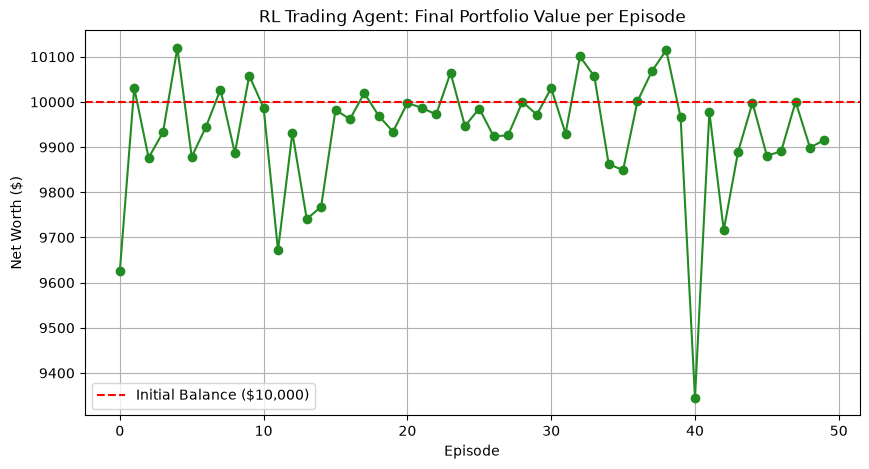

In [3]:
class TradingDQN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(TradingDQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim),
        )

    def forward(self, x):
        return self.net(x)


def train_trading_agent(episodes=50):
    df = fetch_data("AAPL", "2022-01-01", "2023-01-01")
    env = TradingEnv(df)

    initial_state, _ = env.reset()
    state_dim = len(initial_state)
    action_dim = int(getattr(env.action_space, "n", 3))

    q_net = TradingDQN(state_dim, action_dim)
    optimizer = optim.Adam(q_net.parameters(), lr=0.001)
    loss_fn = nn.MSELoss()

    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.95
    gamma = 0.99

    portfolio_history = []

    for ep in range(episodes):
        state, _ = env.reset()
        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)

            if random.random() < epsilon:
                action = int(env.action_space.sample())  # Cast to int for safety
            else:
                with torch.no_grad():
                    action = int(q_net(state_tensor).argmax().item())

            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Simplified online Q-learning update
            next_state_tensor = torch.FloatTensor(next_state).unsqueeze(0)
            with torch.no_grad():
                max_next_q = q_net(next_state_tensor).max().item()
            target_q = float(reward) + gamma * float(max_next_q) * (not done)

            current_q = q_net(state_tensor)[0][action]
            loss = loss_fn(current_q, torch.tensor(target_q, dtype=torch.float32))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            state = next_state

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        portfolio_history.append(env.net_worth)

    return portfolio_history


print("Training Trading Agent...")
net_worth_progression = train_trading_agent(episodes=50)

# Visualize Learning Progress
plt.figure(figsize=(10, 5))
plt.plot(net_worth_progression, color="forestgreen", marker="o")
plt.axhline(y=10000, color="r", linestyle="--", label="Initial Balance ($10,000)")
plt.title("RL Trading Agent: Final Portfolio Value per Episode")
plt.xlabel("Episode")
plt.ylabel("Net Worth ($)")
plt.legend()
plt.grid(True)
plt.show()

## Key Questions

### 1. How can stock trading be represented as an MDP?
* **State ($S$):** The combined representation of market conditions (price, volume, technical indicators) and the agent's internal portfolio status (cash balance, open positions).
* **Action ($A$):** Financial decisions made at each timestep (e.g., Buy, Sell, Hold, or continuous actions representing allocation weights).
* **Reward ($R$):** The financial outcome of an action, typically defined as the step-by-step change in Total Net Worth or Portfolio Value.
* **Transition Dynamics ($P$):** The stochastic shifts in the market from one timestamp to the next, driven by external economic factors.

### 2. What constitutes the state space in financial markets?
The state space requires a blend of external market features and internal agent features to make informed decisions:
* **Market Data:** Open, High, Low, Close (OHLC) prices, trading volume, and order book depth.
* **Derived Technical Indicators:** Simple Moving Averages (SMA), Relative Strength Index (RSI), MACD, or Bollinger Bands to capture momentum and trends.
* **Internal Portfolio Status:** Available purchasing power (cash), current inventory (shares held), and unrealized profit/loss.

### 3. How should rewards be designed to balance profit and risk?
* **Pure Profit (Risk-Neutral):** Setting the reward solely as $R_t = \text{NetWorth}_t - \text{NetWorth}_{t-1}$ encourages the agent to maximize absolute returns, often leading to highly aggressive, volatile strategies.
* **Risk-Adjusted Rewards (Risk-Aware):** Using financial metrics like the **Sharpe Ratio** (Average Return / Standard Deviation of Return) as the reward function penalizes the agent for high volatility. The agent learns to prefer steady, consistent gains over erratic, high-risk gambles.

### 4. What challenges arise from market uncertainty?
* **Non-Stationarity:** Financial markets evolve constantly due to macroeconomic shifts, policy changes, and news. A policy trained on 2020 bull market data will often fail in a 2022 bear market.
* **Low Signal-to-Noise Ratio:** Price movements are heavily obscured by random noise, making it difficult for the neural network to isolate genuine predictive patterns.
* **Hidden Information:** The MDP is partially observable (a POMDP). The agent sees historical prices but does not have access to insider information, breaking news, or global sentiment shifts that actually drive prices.

---

## Supplementary Problems Analysis

### 1. Portfolio Optimization
Instead of a single stock, portfolio optimization expands the action space to a continuous vector of weights $\vec{w}$ (where $\sum w_i = 1$) representing capital allocation across a basket of assets. Actor-Critic algorithms (like DDPG or PPO) are used to adjust these weights dynamically to maximize the portfolio's expected return.

### 2. Risk-Aware Trading
Implemented by shaping the reward function with severe penalties for deep drawdowns. For example, if the portfolio's value drops more than 10% from its peak, a massive negative reward is applied, forcing the agent to learn stop-loss behaviors and position sizing.

### 3. Multi-Asset Trading Strategies
Involves designing an environment where the agent observes a correlation matrix of multiple asset classes (e.g., Equities, Bonds, Commodities). The agent learns hedging strategies—for instance, automatically reallocating capital into gold or bonds when it detects high volatility in equities.